In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [1]:
from google.colab import files
uploaded = files.upload()

Saving Housing.csv to Housing.csv


In [3]:
df=pd.read_csv("Housing.csv")

In [4]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [6]:
df.columns


Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

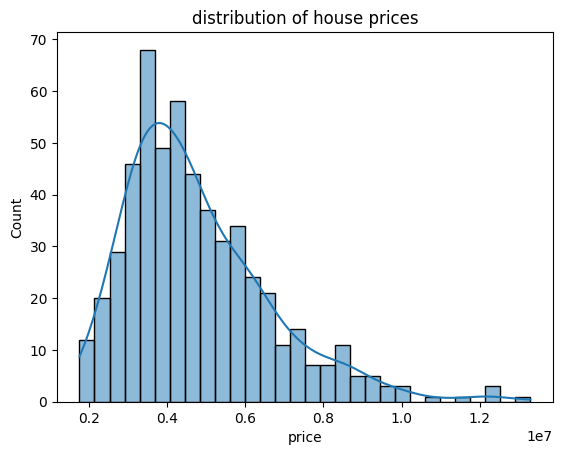

In [8]:
sns.histplot(df['price'], bins=30, kde=True)
plt.title('distribution of house prices')
plt.show()

In [9]:
num_features = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']

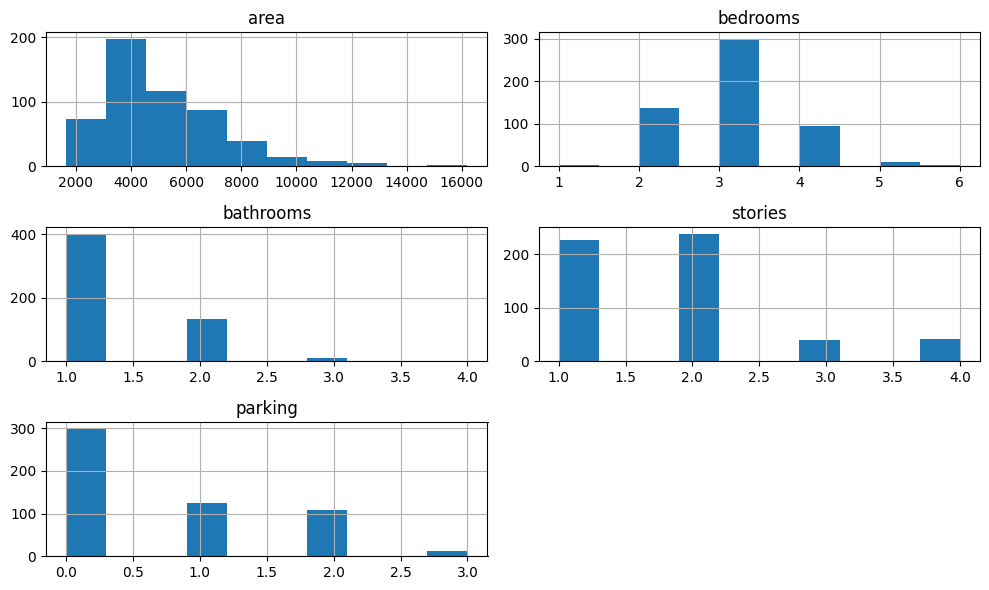

In [14]:
df[num_features].hist(figsize=(10, 6))
plt.tight_layout()
plt.show()

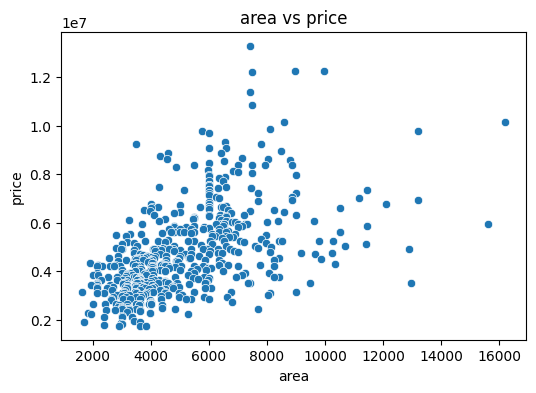

In [15]:
plt.figure(figsize=(6, 4))
sns.scatterplot(x='area', y='price', data=df)
plt.title('area vs price')
plt.show()

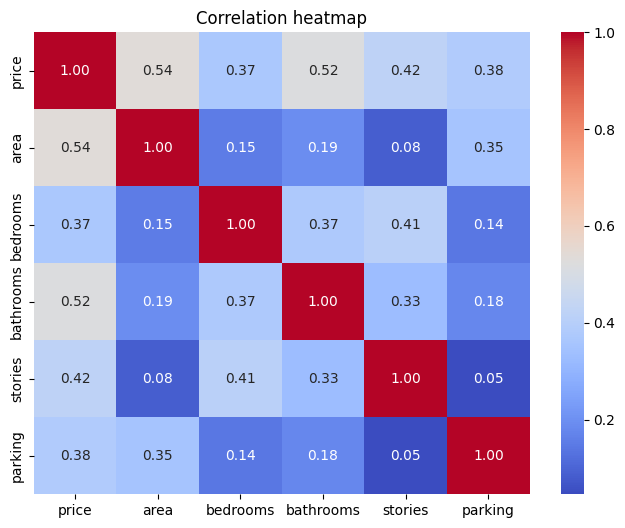

In [16]:
num_df = df.select_dtypes(include=['int64', 'float64'])
correlation = num_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

In [21]:

binary_columns=['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
for col in binary_columns:
  df[col]=df[col].map({'yes':1,'no':0})
df=pd.get_dummies(df,columns=['furnishingstatus'], drop_first=True)


In [22]:
from sklearn.preprocessing import MinMaxScaler
scaler= MinMaxScaler()
features = df.columns.drop('price')
df[features] = scaler.fit_transform(df[features])

In [24]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,0.396564,0.6,0.333333,0.666667,1.0,0.0,0.0,0.0,1.0,0.666667,1.0,0.0,0.0
1,12250000,0.502405,0.6,1.000000,1.000000,1.0,0.0,0.0,0.0,1.0,1.000000,0.0,0.0,0.0
2,12250000,0.571134,0.4,0.333333,0.333333,1.0,0.0,1.0,0.0,0.0,0.666667,1.0,1.0,0.0
3,12215000,0.402062,0.6,0.333333,0.333333,1.0,0.0,1.0,0.0,1.0,1.000000,1.0,0.0,0.0
4,11410000,0.396564,0.6,0.000000,0.333333,1.0,1.0,1.0,0.0,1.0,0.666667,0.0,0.0,0.0


In [25]:
from sklearn.model_selection import train_test_split

In [26]:
X = df.drop('price', axis=1)
y = df['price']

In [27]:
X_train, X_test, y_train, y_test= train_test_split(X,y,test_size=0.2,random_state=42)

In [29]:
from sklearn.linear_model import LinearRegression

In [32]:
model = LinearRegression()
model.fit(X_train, y_train)



LinearRegression()

In [33]:
from sklearn.metrics import r2_score, mean_absolute_error

In [34]:
prediction = model.predict(X_test)

In [36]:
r2 = r2_score(y_test, prediction)
mae = mean_absolute_error(y_test, prediction)

In [37]:
print(f"r sq error is: {r2}")
print(f"mean absolute error: {mae}")

r sq error is: 0.6529242642153172
mean absolute error: 970043.4039201648
